<a href="https://colab.research.google.com/github/radhasundar/datamining/blob/main/exercise3_multiple_linear_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Multiple Linear Regression Model - CO2 dataset

## Import libraries

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split,cross_val_score
from sklearn import linear_model
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error

# Loading the Dataset

In [ ]:
df=pd.read_csv('CO2_data.csv')

In [ ]:
df.head()

,Car,Model,Volume,Weight,CO2
0,Toyoty,Aygo,1000,790,99
1,Mitsubishi,Space Star,1200,1160,95
2,Skoda,Citigo,1000,929,95
3,Fiat,500,900,865,90
4,Mini,Cooper,1500,1140,105


In [ ]:
df.shape

(36, 5)

In [ ]:
print(df.describe())

            Volume       Weight         CO2
count    36.000000    36.000000   36.000000
mean   1611.111111  1292.277778  102.027778
std     388.975047   242.123889    7.454571
min     900.000000   790.000000   90.000000
25%    1475.000000  1117.250000   97.750000
50%    1600.000000  1329.000000   99.000000
75%    2000.000000  1418.250000  105.000000
max    2500.000000  1746.000000  120.000000


#Equation: Sales = β0 + (β1 Weight) + (β2 Volume) + e
##Setting the values for independent (X) variable and dependent (Y) variable

In [ ]:
# setting the value for X and y
X=df[['Weight','Volume']]
y=df['CO2']


# check for outliers

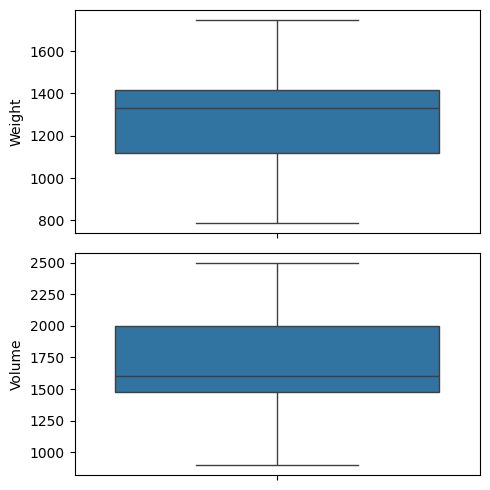

In [ ]:
fig, axs=plt.subplots(2,figsize=(5,5))
plt1=sns.boxplot(df['Weight'],ax=axs[0])
plt2=sns.boxplot(df['Volume'],ax=axs[1])
plt.tight_layout()

Ecploratory data analysis

/tmp/ipython-input-2334567932.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['CO2'])


<Axes: xlabel='CO2', ylabel='Density'>

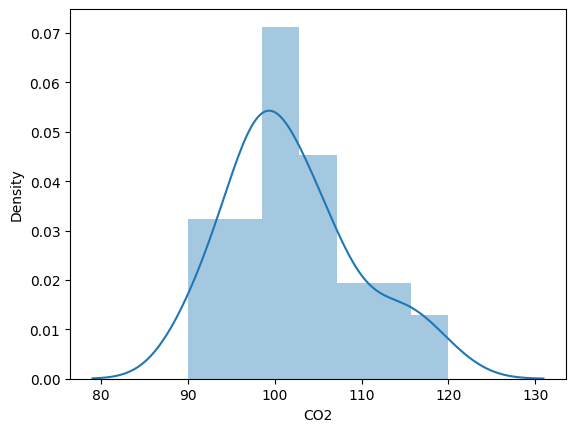

In [ ]:
sns.distplot(df['CO2'])

# the figure shows normal distribution

# Model building

##split the data set into labels and dependent columns

In [ ]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.3,random_state=42)

#Normalization

In [ ]:
y_train.shape

(25,)

In [ ]:
y_test.shape

(11,)

In [ ]:
# fitting the multiple linear regression model
reg_model=LinearRegression().fit(X_train,y_train)

## print the model coefficients

In [ ]:
print('Intercept: ', reg_model.intercept_)
# pair the feature names with the coefficients
print('Coefficients: ')
print(reg_model.coef_)

Intercept:  84.58784534640243
Coefficients: 
[0.00720613 0.00482015]


##Predicting the Test and Train set result

In [ ]:
y_pred=reg_model.predict(X_test)
x_pred=reg_model.predict(X_train)

In [ ]:
model_diff=pd.DataFrame({'Actual Value':y_test,'Predicted Value':y_pred,'Difference':y_test-y_pred})

print(model_diff)

    Actual Value  Predicted Value  Difference
35           120       106.690781   13.309219
13            94       101.322166   -7.322166
26           104       104.965287   -0.965287
30           115       106.276007    8.723993
16            99       102.136459   -3.136459
31           117       106.810057   10.189943
21            99       104.518507   -5.518507
12            99        97.421216    1.578784
8             98        99.831293   -1.831293
17           104       104.416030   -0.416030
9             99       100.587141   -1.587141


Error calculation

In [ ]:
from sklearn import metrics

mae=metrics.mean_absolute_error(y_test,y_pred)
mse=metrics.mean_squared_error(y_test,y_pred)
rmse=np.sqrt(mse)
print('MAE:',mae)
print('MSE:',mse)
print('RMSE:',rmse)
print('variance score: %2f' % reg_model.score(X_test,y_test))

MAE: 4.96171109407186
MSE: 41.85943595384499
RMSE: 6.469886857885923
variance score: 0.410087


# predict CO2 for a new data

In [ ]:
predictCO2=reg_model.predict([[3300,1300]])
print(predictCO2)

[114.63427782]


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
